# Figure 3: Reset Therapy in the ABC Model

**Panel A** — ABC model: roles of A, B, C.

**Panel B** — Continuous treatment: the AB system adapts, B returns to $\mu$ and the tumor's net growth rate $g(B)$ turns positive again (cancer resumes growth).

**Panel C** — Reset therapy: multi-cycle on–off treatment with the optimal $T_{on}$ from Panel D.

**Panel D** — Tumor growth vs. removal over one on–off cycle as a function of $T_{on}$ (fixed $T_{off}$).

**Panel E** — Same as Panel D for a faster-growing tumor (larger $c_1$) and a weaker treatment (smaller $c_2$).

Additional, non-exported analyses and the SI derivation follow the main panels.

In [13]:
"""Shared parameters, ODE model, simulation helpers, and plotting utilities for Figure 3."""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from scipy.integrate import odeint
import sys
sys.path.insert(0, '../src')
from rpa_control.style import set_style
from rpa_control.paths import save_fig
import seaborn as sns

set_style()
plt.rcParams['text.usetex'] = False

# ======================================================================
# Plotting helpers
# ======================================================================

def clean_ax(ax):
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

def text_panel(ax, lines, fontsize=11):
    ax.axis('off')
    ax.text(0.05, 0.95, '\n'.join(lines), transform=ax.transAxes,
            fontsize=fontsize, verticalalignment='top', family='serif', linespacing=1.8)

# ======================================================================
# Parameters
# ======================================================================

mu  = 1.0
a1  = 1.0
b1  = 1.0   # off-treatment
b1_on = b1 / 2   # on-treatment (drug halves b1)
b2  = 2.0
c1  = 0.05   # tumor growth rate
c2  = 1.0   # tumor removal rate
T_OFF = 6.0  # off-treatment duration used in Panels C, C', D

# Off-treatment steady state
B_ss  = mu
A_ss  = b2 * mu / b1
A_ss_on = b2 * mu / b1_on

# On-treatment eigenvalues (A-B subsystem)
disc = b2**2 - 4 * a1 * b1_on
lam1 = (-b2 + np.sqrt(disc)) / 2   # less negative
lam2 = (-b2 - np.sqrt(disc)) / 2   # more negative

# K1 constant for B(t) during treatment
K1 = b2 * mu * (b1_on / b1 - 1) / (lam1 - lam2)

print(f'Off-treatment SS:  A={A_ss:.2f}, B={B_ss:.2f}')
print(f'On-treatment  SS:  A={A_ss_on:.2f}, B={B_ss:.2f}')
print(f'Eigenvalues:  lambda1={lam1:.4f},  lambda2={lam2:.4f}')
print(f'K1 = {K1:.4f}')
S_inf = -c2 * K1 * (-1/lam1 + 1/lam2)
print(f'S_inf = {S_inf:.4f}  (max possible decay per cycle)')

# ======================================================================
# ODE definition
# ======================================================================

def abc_rhs(t, y, b1_val):
    A, B, C = y
    dA = a1 * (mu - B)
    dB = b1_val * A - b2 * B
    dC = C * (c1 - c2 * max(mu - B, 0.0))
    return [dA, dB, dC]

# ======================================================================
# Analytical decay integral S(Ton)
# ======================================================================

def decay_analytic(Ton_arr, T_off, c2=c2):
    """Analytic cumulative tumor decay over one cycle as a function of Ton."""
    Ton_arr = np.asarray(Ton_arr)
    S = -c2 * K1 * (
        np.exp(lam1 * Ton_arr) / lam1
        - np.exp(lam2 * Ton_arr) / lam2
        - 1.0 / lam1
        + 1.0 / lam2
    )
    return S

def growth_analytic(Ton_arr, T_off, c1=c1):
    """Cumulative tumor growth over one cycle (Ton + Toff)."""
    return c1 * (np.asarray(Ton_arr) + T_off)

# Optimal Ton for T_OFF: maximises net removal per cycle (Panel D); used in Panel C
_Ton_scan = np.linspace(0.01, 50, 1000)
Ton_opt_C = _Ton_scan[np.argmax(decay_analytic(_Ton_scan, T_OFF) - growth_analytic(_Ton_scan, T_OFF))]
print(f'Ton_opt (T_off = {T_OFF}) = {Ton_opt_C:.3f}')


Off-treatment SS:  A=2.00, B=1.00
On-treatment  SS:  A=4.00, B=1.00
Eigenvalues:  lambda1=-0.2929,  lambda2=-1.7071
K1 = -0.7071
S_inf = 2.0000  (max possible decay per cycle)
Ton_opt (T_off = 6.0) = 9.067


**Panel A** — ABC system diagram and biological roles.

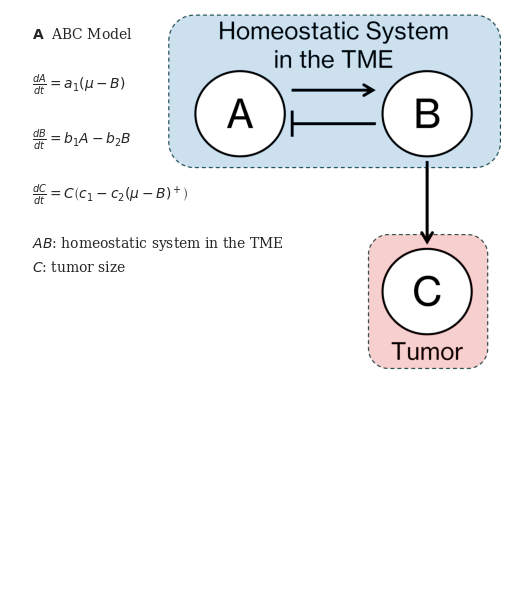

In [14]:
# Panel A: standalone — ABC system diagram + roles
import os

fig_A, ax_A = plt.subplots(figsize=(5, 6))
ax_A.axis('off')

lines_A = [
    r'$\mathbf{A}$  ABC Model',
    '',
    r'$\frac{dA}{dt} = a_1(\mu - B)$',
    '',
    r'$\frac{dB}{dt} = b_1 A - b_2 B$',
    '',
    r'$\frac{dC}{dt} = C\left(c_1 - c_2(\mu-B)^+\right)$',
    '',
    r'$AB$: homeostatic system in the TME',
    r'$C$: tumor size',
]
ax_A.text(0.05, 0.97, '\n'.join(lines_A), transform=ax_A.transAxes,
          fontsize=10, va='top', family='serif', linespacing=1.6)

ABC_IMG = 'abc_model.png'
if os.path.exists(ABC_IMG):
    ax_img = ax_A.inset_axes([0.25, 0.35, 1.0, 0.65])
    ax_img.imshow(plt.imread(ABC_IMG))
    ax_img.axis('off')

plt.tight_layout()
plt.show()


**Panel B** — Continuous treatment: cancer resumes growth.

Figure saved to /home/amir/RL/autodiff-control/plots/figure3_B.pdf


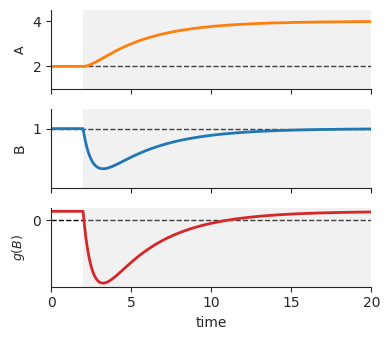

In [25]:
# ======================================================================
# Panel B: cancer resumes growth
# ======================================================================
from scipy.optimize import brentq
from matplotlib.transforms import ScaledTranslation, blended_transform_factory

Ton_B  = 20.0
Toff_B = 2
C0_B   = 1.0
epsilon = 0.1
y0_B   = [A_ss, B_ss, C0_B]

lw = 2

_t_off  = np.linspace(0, Toff_B, 2000)
_sol_off = odeint(lambda y, t: abc_rhs(t, y, b1), y0_B, _t_off)

_t_on  = np.linspace(0, Ton_B, 2000)
_sol_on = odeint(lambda y, t: abc_rhs(t, y, b1_on), list(_sol_off[-1]), _t_on)


t_B = np.concatenate([_t_off, Toff_B + _t_on[1:]])
A_B = np.concatenate([_sol_off[:, 0], _sol_on[1:, 0]])
B_B = np.concatenate([_sol_off[:, 1], _sol_on[1:, 1]])
C_B = np.concatenate([_sol_off[:, 2], _sol_on[1:, 2]])


t_AB_mark = 13.0

# ── Plot ──────────────────────────────────────────────────────────────
fig_B, axes_B = plt.subplots(
    nrows=3, ncols=1, 
    figsize=(4, 3.5), sharex=True
    )

# A
ax = axes_B[0]
ax.plot(t_B, A_B, color='C1', lw=lw)
ax.axhline(2,  color='black', ls='--', lw=1, zorder=-1)
ax.set_ylim(1,4.5)
ax.set_ylabel('A', fontsize=9)
ax.set_yticks([2, 4])

# B
ax = axes_B[1]
ax.set_ylim(top=1.2)
ax.plot(t_B, B_B, color='C0', lw=lw)
ax.set_ylim(bottom=0.4)
ax.axhline(1,  color='black', ls='--', lw=1, zorder=-1)
ax.set_ylabel('B')
ax.set_yticks([1])

# C 
ax = axes_B[2]
ax.plot(t_B, c1 - c2 * np.maximum(mu - B_B, 0.0), color='C3', lw=lw)
ax.axhline(0,  color='black', ls='--', lw=1, zorder=-1)
ax.set_ylabel('$g(B)$', fontsize=9)
ax.set_xlabel('time')
ax.set_yticks([0])

# integer ticks every 5 steps:
ax.set_xticks(np.arange(0, 25, 5))


for ax in axes_B:
    ax.set_xlim(0, 20)
    ax.axvspan(Toff_B, Ton_B, color='lightgray', alpha=0.3, lw=0, zorder=0)
    sns.despine(ax=ax)

save_fig(fig_B, 'figure3_B.pdf')


plt.tight_layout()
plt.show()


**Panel C** — Reset therapy: multi-cycle simulation with the optimal $T_{on}$ (from Panel D) and $T_{off}$ = `T_OFF`.

T on: 9.067. Toff: 6.0


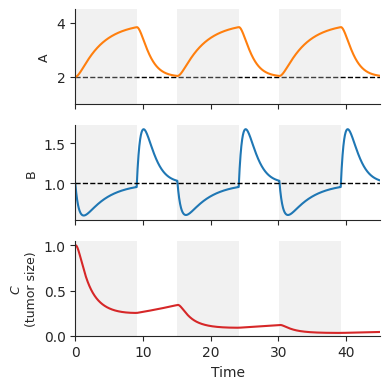

Figure saved to /home/amir/RL/autodiff-control/plots/figure3_C.pdf


In [29]:
# ======================================================================
# Panel C: reset therapy — multi-cycle simulation with Ton_opt_C
# ======================================================================

T_horizon = 100.0
Ton_D  = Ton_opt_C
Toff_D = T_OFF

t_all, A_all, B_all, C_all = [], [], [], []
on_spans = []
y_cur = [A_ss, B_ss, 1.0]
t_cur = 0.0

while t_cur < T_horizon:
    # ON phase
    t_on = min(Ton_D, T_horizon - t_cur)
    t_seg = np.linspace(0, t_on, 400)
    s_on = odeint(lambda y, t: abc_rhs(t, y, b1_on), y_cur, t_seg)
    on_spans.append((t_cur, t_cur + t_on))
    t_all.append(t_cur + t_seg)
    A_all.append(s_on[:, 0]); B_all.append(s_on[:, 1]); C_all.append(s_on[:, 2])
    t_cur += t_on; y_cur = s_on[-1]
    if t_cur >= T_horizon:
        break
    # OFF phase
    t_off = min(Toff_D, T_horizon - t_cur)
    t_seg = np.linspace(0, t_off, 400)
    s_off = odeint(lambda y, t: abc_rhs(t, y, b1), y_cur, t_seg)
    t_all.append(t_cur + t_seg)
    A_all.append(s_off[:, 0]); B_all.append(s_off[:, 1]); C_all.append(s_off[:, 2])
    t_cur += t_off; y_cur = s_off[-1]

t_cyc = np.concatenate(t_all)
A_cyc = np.concatenate(A_all)
B_cyc = np.concatenate(B_all)
C_cyc = np.concatenate(C_all)

# ── Plot ──────────────────────────────────────────────────────────────
fig_D, axes_D = plt.subplots(
        nrows=3, ncols=1, 
    figsize=(4, 4), sharex=True
)

axs = axes_D


# A
ax = axes_D[0]
ax.plot(t_cyc, A_cyc, color='C1', lw=1.5)
ax.set_ylabel('A', fontsize=9)
ax.set_ylim(1,4.5)
ax.axhline(2,  color='black', ls='--', lw=1, zorder=-1)

# B
ax = axes_D[1]
ax.plot(t_cyc, B_cyc, color='C0', lw=1.5)
ax.axhline(mu, color='black', ls='--', lw=1)
ax.set_ylabel('B', fontsize=9)

# C 
ax = axes_D[2]
ax.plot(t_cyc, C_cyc, color='C3', lw=1.5)
ax.set_ylabel('$C$\n(tumor size)', fontsize=9)
ax.set_xlabel('Time', fontsize=10)
ax.set_ylim(bottom=0)



for ax in axs:
    for t_start, t_end in on_spans:
        ax.axvspan(t_start, t_end, color='lightgray', alpha=0.3, lw=0, zorder=0)

    ax.set_xlim(0,45)
    sns.despine(ax=ax)

print(f'T on: {Ton_opt_C:.3f}. Toff: {Toff_D}')

plt.tight_layout()
plt.show()

save_fig(fig_D, 'figure3_C.pdf')

**Panel D** — Growth vs. removal for fixed $T_{off}$, with the optimal $T_{on}$ window.

T_off = 6.0
Crossing points (growth = decay): ['1.215', '33.998']
Ton that maximises net decay: 9.067


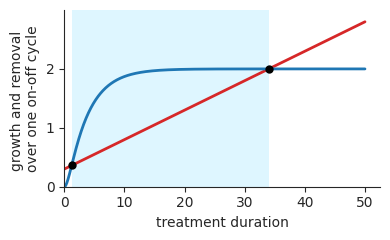


Using Ton_opt = 9.067 for Panel D
Figure saved to /home/amir/RL/autodiff-control/plots/figure3_D.pdf


In [30]:
# ======================================================================
# Panel D: growth vs. removal with 3-regime annotations
# ======================================================================
from scipy.optimize import brentq

Ton_arr = np.linspace(0.01, 50, 1000)

growth_arr = growth_analytic(Ton_arr, T_OFF)
decay_arr  = decay_analytic(Ton_arr, T_OFF)
net_arr    = decay_arr - growth_arr   # positive → tumor shrinks

# Find the two crossing points (decay == growth)
sign_changes = np.where(np.diff(np.sign(net_arr)))[0]
crossings = []
crossings_visual = []   # (x, y) on the drawn piecewise-linear curves
for idx in sign_changes:
    ta, tb = Ton_arr[idx], Ton_arr[idx + 1]
    root = brentq(lambda t: decay_analytic(t, T_OFF) - growth_analytic(t, T_OFF), ta, tb)
    crossings.append(root)
    _frac = -net_arr[idx] / (net_arr[idx+1] - net_arr[idx])
    _cx_v = ta + _frac * (tb - ta)
    _val_v = growth_arr[idx] + _frac * (growth_arr[idx+1] - growth_arr[idx])
    crossings_visual.append((_cx_v, _val_v))

print(f'T_off = {T_OFF}')
print(f'Crossing points (growth = decay): {[f"{c:.3f}" for c in crossings]}')
Ton_max_net = Ton_arr[np.argmax(net_arr)]
print(f'Ton that maximises net decay: {Ton_max_net:.3f}')

# ── Plot ──────────────────────────────────────────────────────────────
fig_C, ax_C = plt.subplots(figsize=(4, 2.5))

ax = ax_C

x_max = Ton_arr[-1]
regime_alpha = 0.10
if len(crossings) >= 2:
    c1_x, c2_x = crossings[0], crossings[1]
    ax_C.axvspan(c1_x,       c2_x, color='deepskyblue', alpha=regime_alpha + 0.03, lw=0)

# Main curves
ax_C.plot(Ton_arr, growth_arr, color='C3', lw=2)
ax_C.plot(Ton_arr, decay_arr,  color='C0', lw=2)
ax_C.axhline(0, color='k', lw=0.5)
from matplotlib.transforms import ScaledTranslation
_nudge_C = ScaledTranslation(0, 0.5/72, fig_C.dpi_scale_trans)
_trans_C = lambda ax: ax.transData + _nudge_C


# Crossing point markers
for _cx_v, _val_v in crossings_visual:
    ax_C.plot(_cx_v, _val_v, 'o', color='k', ms=6, zorder=6, mec='none')

# Regime text annotations
_y_max    = max(growth_arr.max(), decay_arr.max())
_regime_y1 = _y_max * 0.60
_regime_y2 = _y_max * 0.58
_regime_y3 = _y_max * 0.60

# Optimal Ton: line ending at top curve, with intersection dots
_y_grow_opt = growth_analytic(Ton_max_net, T_OFF)
_y_dec_opt  = decay_analytic(Ton_max_net, T_OFF)
_y_top_opt  = max(_y_grow_opt, _y_dec_opt)


ax_C.set_xlabel('treatment duration')
ax_C.set_ylabel('growth and removal \nover one on-off cycle')


ax.set_ylim(bottom=0, top=3)
ax.set_xlim(left=0)

ax.set_yticks([0, 1, 2])

clean_ax(ax_C)
plt.tight_layout()
plt.show()

# Store the optimal Ton for Panel D
Ton_opt_C = Ton_max_net
print(f'\nUsing Ton_opt = {Ton_opt_C:.3f} for Panel D')

save_fig(fig_C, 'figure3_D.pdf')


**Panel E** — Growth vs. removal for a faster-growing tumor (larger $c_1$) and a weaker treatment (smaller $c_2$).

T_off = 6.0
Crossing points (growth = decay): ['3.539', '9.375']
Ton that maximises net decay: 6.065


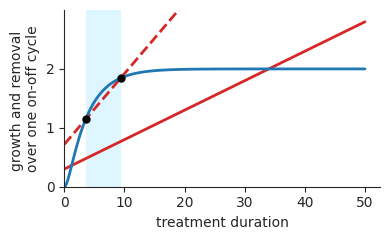


Optimal Ton (c1=0.12) = 6.065
Figure saved to /home/amir/RL/autodiff-control/plots/figure3_E_high_growth.pdf


In [31]:
# ======================================================================
# Panel E: faster-growing tumor (larger c1)
# ======================================================================

larger_c1 = 0.12

from scipy.optimize import brentq

Ton_arr = np.linspace(0.01, 50, 1000)

base_growth_arr = growth_analytic(Ton_arr, T_OFF, c1=c1)
growth_arr = growth_analytic(Ton_arr, T_OFF, c1=larger_c1)
decay_arr  = decay_analytic(Ton_arr, T_OFF)
net_arr    = decay_arr - growth_arr   # positive → tumor shrinks

# Find the two crossing points (decay == growth)
sign_changes = np.where(np.diff(np.sign(net_arr)))[0]
crossings = []
crossings_visual = []   # (x, y) on the drawn piecewise-linear curves
for idx in sign_changes:
    ta, tb = Ton_arr[idx], Ton_arr[idx + 1]
    root = brentq(lambda t: decay_analytic(t, T_OFF) - growth_analytic(t, T_OFF, c1=larger_c1), ta, tb)
    crossings.append(root)
    _frac = -net_arr[idx] / (net_arr[idx+1] - net_arr[idx])
    _cx_v = ta + _frac * (tb - ta)
    _val_v = growth_arr[idx] + _frac * (growth_arr[idx+1] - growth_arr[idx])
    crossings_visual.append((_cx_v, _val_v))

print(f'T_off = {T_OFF}')
print(f'Crossing points (growth = decay): {[f"{c:.3f}" for c in crossings]}')
Ton_max_net = Ton_arr[np.argmax(net_arr)]
print(f'Ton that maximises net decay: {Ton_max_net:.3f}')

# ── Plot ──────────────────────────────────────────────────────────────
fig_C, ax_C = plt.subplots(figsize=(4, 2.5))

ax = ax_C

x_max = Ton_arr[-1]
regime_alpha = 0.10
if len(crossings) >= 2:
    c1_x, c2_x = crossings[0], crossings[1]
    ax_C.axvspan(c1_x,       c2_x, color='deepskyblue', alpha=regime_alpha + 0.03, lw=0)

# Main curves
ax_C.plot(Ton_arr, growth_arr, color='C3', lw=2, linestyle='--')
ax_C.plot(Ton_arr, base_growth_arr, color='C3', lw=2)
ax_C.plot(Ton_arr, decay_arr,  color='C0', lw=2)
ax_C.axhline(0, color='k', lw=0.5)
from matplotlib.transforms import ScaledTranslation
_nudge_C = ScaledTranslation(0, 0.5/72, fig_C.dpi_scale_trans)
_trans_C = lambda ax: ax.transData + _nudge_C


# Crossing point markers
for _cx_v, _val_v in crossings_visual:
    ax_C.plot(_cx_v, _val_v, 'o', color='k', ms=6, zorder=6, mec='none')

# Regime text annotations
_y_max    = max(growth_arr.max(), decay_arr.max())
_regime_y1 = _y_max * 0.60
_regime_y2 = _y_max * 0.58
_regime_y3 = _y_max * 0.60

ax_C.set_xlabel('treatment duration')
ax_C.set_ylabel('growth and removal \nover one on-off cycle')


ax.set_ylim(bottom=0, top=3)
ax.set_xlim(left=0)

ax.set_yticks([0, 1, 2])


clean_ax(ax_C)
plt.tight_layout()
plt.show()

Ton_opt_highgrowth = Ton_max_net
print(f'\nOptimal Ton (c1={larger_c1}) = {Ton_opt_highgrowth:.3f}')

save_fig(fig_C, 'figure3_E_high_growth.pdf')




T_off = 6.0
Crossing points (growth = decay): ['3.975', '8.303']
Ton that maximises net decay: 5.915


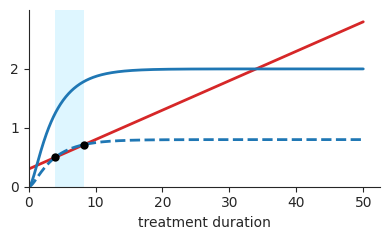


Optimal Ton (c2=0.4) = 5.915
Figure saved to /home/amir/RL/autodiff-control/plots/figure3_E_weak_treatment.pdf


In [32]:
# ======================================================================
# Panel E: weaker treatment (smaller c2)
# ======================================================================

smaller_c2 = 0.4

from scipy.optimize import brentq

Ton_arr = np.linspace(0.01, 50, 1000)

base_decay_arr = decay_analytic(Ton_arr, T_OFF, c2=c2)
growth_arr = growth_analytic(Ton_arr, T_OFF, c1=c1)
decay_arr  = decay_analytic(Ton_arr, T_OFF, c2=smaller_c2)
net_arr    = decay_arr - growth_arr   # positive → tumor shrinks

# Find the two crossing points (decay == growth)
sign_changes = np.where(np.diff(np.sign(net_arr)))[0]
crossings = []
crossings_visual = []   # (x, y) on the drawn piecewise-linear curves
for idx in sign_changes:
    ta, tb = Ton_arr[idx], Ton_arr[idx + 1]
    root = brentq(lambda t: decay_analytic(t, T_OFF, c2=smaller_c2) - growth_analytic(t, T_OFF, c1=c1), ta, tb)
    crossings.append(root)
    _frac = -net_arr[idx] / (net_arr[idx+1] - net_arr[idx])
    _cx_v = ta + _frac * (tb - ta)
    _val_v = growth_arr[idx] + _frac * (growth_arr[idx+1] - growth_arr[idx])
    crossings_visual.append((_cx_v, _val_v))

print(f'T_off = {T_OFF}')
print(f'Crossing points (growth = decay): {[f"{c:.3f}" for c in crossings]}')
Ton_max_net = Ton_arr[np.argmax(net_arr)]
print(f'Ton that maximises net decay: {Ton_max_net:.3f}')

# ── Plot ──────────────────────────────────────────────────────────────
fig_C, ax_C = plt.subplots(figsize=(4, 2.5))

ax = ax_C

x_max = Ton_arr[-1]
regime_alpha = 0.10
if len(crossings) >= 2:
    c1_x, c2_x = crossings[0], crossings[1]
    ax_C.axvspan(c1_x,       c2_x, color='deepskyblue', alpha=regime_alpha + 0.03, lw=0)

# Main curves
ax_C.plot(Ton_arr, growth_arr, color='C3', lw=2)
ax_C.plot(Ton_arr, base_decay_arr,  color='C0', lw=2)
ax_C.plot(Ton_arr, decay_arr,  color='C0', lw=2, linestyle='--')

ax_C.axhline(0, color='k', lw=0.5)
from matplotlib.transforms import ScaledTranslation
_nudge_C = ScaledTranslation(0, 0.5/72, fig_C.dpi_scale_trans)
_trans_C = lambda ax: ax.transData + _nudge_C


# Crossing point markers
for _cx_v, _val_v in crossings_visual:
    ax_C.plot(_cx_v, _val_v, 'o', color='k', ms=6, zorder=6, mec='none')

# Regime text annotations
_y_max    = max(growth_arr.max(), decay_arr.max())
_regime_y1 = _y_max * 0.60
_regime_y2 = _y_max * 0.58
_regime_y3 = _y_max * 0.60

ax_C.set_xlabel('treatment duration')
# ax_C.set_ylabel('growth and removal \nover one on-off cycle')


ax.set_ylim(bottom=0, top=3)
ax.set_xlim(left=0)

ax.set_yticks([0, 1, 2])


clean_ax(ax_C)
plt.tight_layout()
plt.show()

Ton_opt_loweff = Ton_max_net
print(f'\nOptimal Ton (c2={smaller_c2}) = {Ton_opt_loweff:.3f}')

save_fig(fig_C, 'figure3_E_weak_treatment.pdf')




## Additional analyses (not exported)

Single on–off cycle showing timescale separation: AB recovers before C.

/tmp/ipykernel_1096524/516566122.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


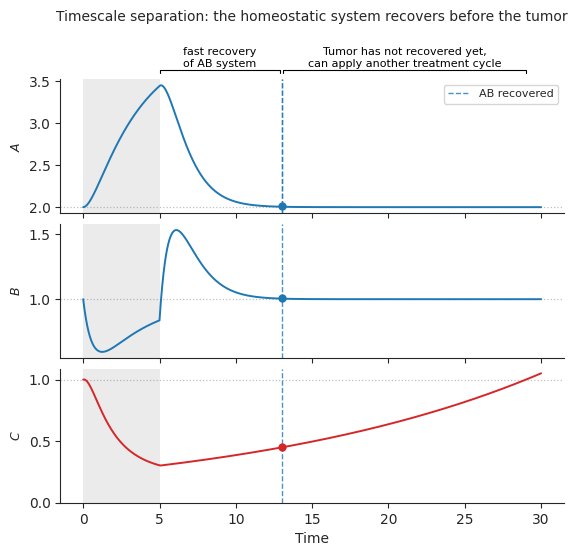

In [20]:
# ======================================================================
# Extra: timescale separation — AB recovers before C
# ======================================================================
from scipy.optimize import brentq
from matplotlib.transforms import ScaledTranslation, blended_transform_factory

Ton_B  = 5.0
Toff_B = 25.0
C0_B   = 1.0
epsilon = 0.1
y0_B   = [A_ss, B_ss, C0_B]

_t_on  = np.linspace(0, Ton_B, 2000)
_sol_on = odeint(lambda y, t: abc_rhs(t, y, b1_on), y0_B, _t_on)
_t_off  = np.linspace(0, Toff_B, 2000)
_sol_off = odeint(lambda y, t: abc_rhs(t, y, b1), list(_sol_on[-1]), _t_off)

t_B = np.concatenate([_t_on, Ton_B + _t_off[1:]])
A_B = np.concatenate([_sol_on[:, 0], _sol_off[1:, 0]])
B_B = np.concatenate([_sol_on[:, 1], _sol_off[1:, 1]])
C_B = np.concatenate([_sol_on[:, 2], _sol_off[1:, 2]])

_imin = C_B.argmin()
_t_after = t_B[_imin:]; _C_after = C_B[_imin:]
_sc = np.where(np.diff(np.sign(_C_after - C0_B)) > 0)[0]
t_C_rec_B = brentq(lambda t: np.interp(t, t_B, C_B) - C0_B,
                   _t_after[_sc[0]], _t_after[_sc[0]+1])

t_AB_mark = 13.0

# ── Plot ──────────────────────────────────────────────────────────────
fig_B, axes_B = plt.subplots(3, 1, figsize=(6.5, 5.5), sharex=True,
                              gridspec_kw={'hspace': 0.08})
_nudge_B = ScaledTranslation(0, 0.5/72, fig_B.dpi_scale_trans)
_trans_B = lambda ax: ax.transData + _nudge_B

for ax in axes_B:
    ax.axvspan(0, Ton_B, color='lightgray', alpha=0.45, lw=0, zorder=0)
    clean_ax(ax)

axes_B[0].axhline(A_ss,  color='gray', ls=':', lw=0.9, alpha=0.5)
axes_B[1].axhline(mu,    color='gray', ls=':', lw=0.9, alpha=0.5)
axes_B[2].axhline(C0_B,  color='gray', ls=':', lw=0.9, alpha=0.5)

axes_B[0].plot(t_B, A_B, color='C0', lw=1.4)
axes_B[1].plot(t_B, B_B, color='C0', lw=1.4)
axes_B[2].plot(t_B, C_B, color='C3', lw=1.4)

# Vertical line: AB recovered
for ax in axes_B:
    ax.axvline(t_AB_mark, color='C0', ls='--', lw=1.0, alpha=0.8)
axes_B[0].axvline(t_AB_mark, color='C0', ls='--', lw=1.0, alpha=0.8, label='AB recovered')
axes_B[0].plot(t_AB_mark, np.interp(t_AB_mark, t_B, A_B), 'o', color='C0', ms=6, zorder=6, mec='none', transform=_trans_B(axes_B[0]))
axes_B[1].plot(t_AB_mark, np.interp(t_AB_mark, t_B, B_B), 'o', color='C0', ms=6, zorder=6, mec='none', transform=_trans_B(axes_B[1]))
axes_B[2].plot(t_AB_mark, np.interp(t_AB_mark, t_B, C_B), 'o', color='C3', ms=6, zorder=6, mec='none', transform=_trans_B(axes_B[2]))

# Bracket annotations above top subplot
_bt_B = blended_transform_factory(axes_B[0].transData, axes_B[0].transAxes)
_y_bar, _tick_h = 1.07, 0.025

def _draw_bracket(ax, x1, x2, text, y_bar, tick_h, trans, fs=8):
    for _xb in [x1, x2]:
        ax.plot([_xb, _xb], [y_bar - tick_h, y_bar], 'k-', lw=0.8,
                transform=trans, clip_on=False)
    ax.plot([x1, x2], [y_bar, y_bar], 'k-', lw=0.8,
            transform=trans, clip_on=False)
    ax.text((x1 + x2) / 2, y_bar + 0.01, text,
            ha='center', va='bottom', fontsize=fs, color='k',
            transform=trans, clip_on=False)

_draw_bracket(axes_B[0], Ton_B, t_AB_mark - epsilon,
              'fast recovery\nof AB system',
              _y_bar, _tick_h, _bt_B)
_draw_bracket(axes_B[0], t_AB_mark + epsilon, t_C_rec_B,
              'Tumor has not recovered yet,\ncan apply another treatment cycle',
              _y_bar, _tick_h, _bt_B)

axes_B[0].set_ylabel('$A$', fontsize=9)
axes_B[1].set_ylabel('$B$', fontsize=9)
axes_B[2].set_ylabel('$C$', fontsize=9)
axes_B[2].set_xlabel('Time', fontsize=10)
axes_B[0].legend(fontsize=8, loc='upper right')
axes_B[2].set_ylim(bottom=0)
axes_B[0].tick_params(labelbottom=False)
axes_B[1].tick_params(labelbottom=False)

axes_B[0].set_title(
    r'Timescale separation: the homeostatic system recovers before the tumor',
    fontsize=10, pad=42)

plt.tight_layout()
plt.show()


Optimal vs. sub-optimal $T_{on}$ (treatment too long regime), both with $T_{off}$ = `T_OFF`.

/tmp/ipykernel_1096524/2482105036.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


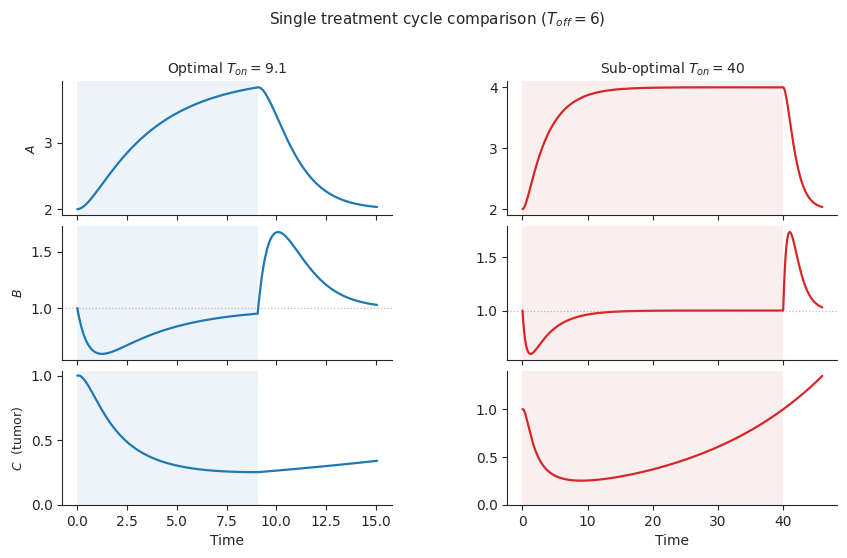

In [21]:
# ======================================================================
# Extra: optimal vs sub-optimal Ton — single cycle, two separate plots
# ======================================================================
Ton_opt_Cp  = Ton_opt_C        # optimal from Panel C
Ton_sub_Cp  = 40.0             # sub-optimal: 'treatment too long' regime
Toff_Cp     = T_OFF            # same Toff as Panel C

_cases = [
    dict(Ton=Ton_opt_Cp, color='C0', title=rf'Optimal $T_{{on}}={Ton_opt_Cp:.1f}$'),
    dict(Ton=Ton_sub_Cp, color='C3', title=rf'Sub-optimal $T_{{on}}={Ton_sub_Cp:.0f}$'),
]

_sims = []
for _c in _cases:
    _y0 = [A_ss, B_ss, 1.0]
    _t_on  = np.linspace(0, _c['Ton'], 1200)
    _sol_on = odeint(lambda y, t: abc_rhs(t, y, b1_on), _y0, _t_on)
    _t_off  = np.linspace(0, Toff_Cp, 400)
    _sol_off = odeint(lambda y, t: abc_rhs(t, y, b1), list(_sol_on[-1]), _t_off)
    _t   = np.concatenate([_t_on, _c['Ton'] + _t_off[1:]])
    _sol = np.concatenate([_sol_on, _sol_off[1:]])
    _sims.append(dict(t=_t, A=_sol[:,0], B=_sol[:,1], C=_sol[:,2], **_c))

# ── Plot: 2 columns × 3 rows ──────────────────────────────────────────
fig_Cp, axes_Cp = plt.subplots(3, 2, figsize=(10, 5.5),
                                gridspec_kw={'hspace': 0.08, 'wspace': 0.35})

for col, _d in enumerate(_sims):
    axs = axes_Cp[:, col]
    for _ax in axs:
        _ax.axvspan(0, _d['Ton'], color=_d['color'], alpha=0.08, lw=0, zorder=0)
        clean_ax(_ax)

    axs[0].plot(_d['t'], _d['A'], color=_d['color'], lw=1.6)
    axs[1].plot(_d['t'], _d['B'], color=_d['color'], lw=1.6)
    axs[1].axhline(mu, color='gray', ls=':', lw=0.9, alpha=0.5)
    axs[2].plot(_d['t'], _d['C'], color=_d['color'], lw=1.6)

    axs[2].set_xlabel('Time', fontsize=10)
    axs[2].set_ylim(bottom=0)
    axs[0].tick_params(labelbottom=False)
    axs[1].tick_params(labelbottom=False)
    axs[0].set_title(_d['title'], fontsize=10)

# y-labels on left column only
axes_Cp[0, 0].set_ylabel('$A$', fontsize=9)
axes_Cp[1, 0].set_ylabel('$B$', fontsize=9)
axes_Cp[2, 0].set_ylabel('$C$  (tumor)', fontsize=9)

fig_Cp.suptitle(rf'Single treatment cycle comparison ($T_{{off}}={Toff_Cp:.0f}$)',
                fontsize=11, y=1.01)

plt.tight_layout()
plt.show()


Multi-cycle simulation with the optimal $T_{on}$, detailed version of Panel C (with steady-state reference lines).

/tmp/ipykernel_1096524/1224169764.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


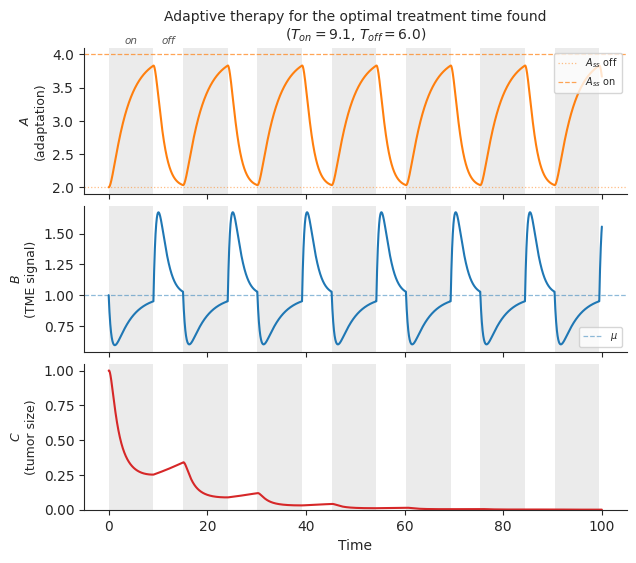

In [22]:
# ======================================================================
# Extra: multi-cycle simulation with Ton_opt_C (detailed version of Panel C)
# ======================================================================

T_horizon = 100.0
Ton_D  = Ton_opt_C
Toff_D = T_OFF

t_all, A_all, B_all, C_all = [], [], [], []
on_spans = []
y_cur = [A_ss, B_ss, 1.0]
t_cur = 0.0

while t_cur < T_horizon:
    # ON phase
    t_on = min(Ton_D, T_horizon - t_cur)
    t_seg = np.linspace(0, t_on, 400)
    s_on = odeint(lambda y, t: abc_rhs(t, y, b1_on), y_cur, t_seg)
    on_spans.append((t_cur, t_cur + t_on))
    t_all.append(t_cur + t_seg)
    A_all.append(s_on[:, 0]); B_all.append(s_on[:, 1]); C_all.append(s_on[:, 2])
    t_cur += t_on; y_cur = s_on[-1]
    if t_cur >= T_horizon:
        break
    # OFF phase
    t_off = min(Toff_D, T_horizon - t_cur)
    t_seg = np.linspace(0, t_off, 400)
    s_off = odeint(lambda y, t: abc_rhs(t, y, b1), y_cur, t_seg)
    t_all.append(t_cur + t_seg)
    A_all.append(s_off[:, 0]); B_all.append(s_off[:, 1]); C_all.append(s_off[:, 2])
    t_cur += t_off; y_cur = s_off[-1]

t_cyc = np.concatenate(t_all)
A_cyc = np.concatenate(A_all)
B_cyc = np.concatenate(B_all)
C_cyc = np.concatenate(C_all)

# ── Plot ──────────────────────────────────────────────────────────────
fig_D, axes_D = plt.subplots(3, 1, figsize=(7, 6), sharex=True,
                              gridspec_kw={'hspace': 0.08})

for t_start, t_end in on_spans:
    for ax in axes_D:
        ax.axvspan(t_start, t_end, color='lightgray', alpha=0.45, lw=0, zorder=0)

for ax in axes_D:
    clean_ax(ax)

axes_D[0].plot(t_cyc, A_cyc, color='C1', lw=1.5)
axes_D[0].axhline(A_ss,    color='C1', ls=':',  lw=0.9, alpha=0.5, label=f'$A_{{ss}}$ off')
axes_D[0].axhline(A_ss_on, color='C1', ls='--', lw=0.9, alpha=0.7, label=f'$A_{{ss}}$ on')
axes_D[0].set_ylabel('$A$\n(adaptation)', fontsize=9)
axes_D[0].legend(fontsize=7, loc='upper right')

axes_D[1].plot(t_cyc, B_cyc, color='C0', lw=1.5)
axes_D[1].axhline(mu, color='C0', ls='--', lw=0.9, alpha=0.5, label=r'$\mu$')
axes_D[1].set_ylabel('$B$\n(TME signal)', fontsize=9)
axes_D[1].legend(fontsize=7, loc='lower right')

axes_D[2].plot(t_cyc, C_cyc, color='C3', lw=1.5)
axes_D[2].set_ylabel('$C$\n(tumor size)', fontsize=9)
axes_D[2].set_xlabel('Time', fontsize=10)
axes_D[2].set_ylim(bottom=0)

# Annotate on/off
trans = axes_D[0].get_xaxis_transform()
kw_lbl = dict(ha='center', va='bottom', fontsize=7.5, color='#555555',
              fontstyle='italic', transform=trans)
if on_spans:
    t0_on, t1_on = on_spans[0]
    axes_D[0].text((t0_on + t1_on) / 2, 1.01, 'on', **kw_lbl)
    if len(on_spans) > 1:
        t_off_start = t1_on
        t_off_end   = on_spans[1][0]
        axes_D[0].text((t_off_start + t_off_end) / 2, 1.01, 'off', **kw_lbl)

axes_D[0].set_title(
    f'Adaptive therapy for the optimal treatment time found\n'
    rf'($T_{{on}}={Ton_D:.1f}$, $T_{{off}}={Toff_D:.1f}$)',
    fontsize=10)

plt.tight_layout()
plt.show()

Robustness of reset therapy to noise in $T_{on}$ and $T_{off}$ (schedule $T_{on} = T_{off} = 10$): a single noisy run, then 500 noisy runs vs. the noise-free schedule.

/tmp/ipykernel_1096524/1269388721.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


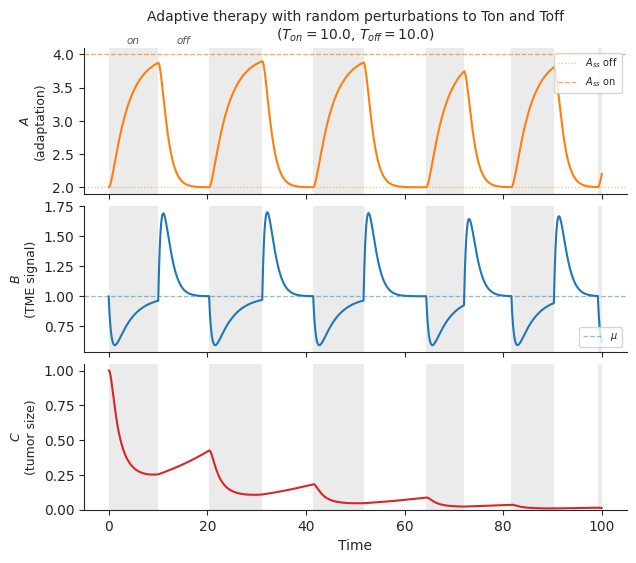

In [23]:
# Extra: Ton = Toff = 10 schedule with perturbations to Ton and Toff to show robustness

T_horizon = 100.0
Ton_D  = 10.0
Toff_D = 10.0
noise_level = 1.0

t_all, A_all, B_all, C_all = [], [], [], []
on_spans = []
y_cur = [A_ss, B_ss, 1.0]
t_cur = 0.0

while t_cur < T_horizon:
    # ON phase
    # add noise to Ton
    Ton_D_noised = Ton_D + np.random.normal(0, noise_level)
    t_on = min(Ton_D_noised, T_horizon - t_cur)
    t_seg = np.linspace(0, t_on, 400)
    s_on = odeint(lambda y, t: abc_rhs(t, y, b1_on), y_cur, t_seg)
    on_spans.append((t_cur, t_cur + t_on))
    t_all.append(t_cur + t_seg)
    A_all.append(s_on[:, 0]); B_all.append(s_on[:, 1]); C_all.append(s_on[:, 2])
    t_cur += t_on; y_cur = s_on[-1]
    if t_cur >= T_horizon:
        break
    # OFF phase
    # add noise to Toff
    Toff_D_noised = Toff_D + np.random.normal(0, noise_level)
    t_off = min(Toff_D_noised, T_horizon - t_cur)
    t_seg = np.linspace(0, t_off, 400)
    s_off = odeint(lambda y, t: abc_rhs(t, y, b1), y_cur, t_seg)
    t_all.append(t_cur + t_seg)
    A_all.append(s_off[:, 0]); B_all.append(s_off[:, 1]); C_all.append(s_off[:, 2])
    t_cur += t_off; y_cur = s_off[-1]

t_cyc = np.concatenate(t_all)
A_cyc = np.concatenate(A_all)
B_cyc = np.concatenate(B_all)
C_cyc = np.concatenate(C_all)

# ── Plot ──────────────────────────────────────────────────────────────
fig_D, axes_D = plt.subplots(3, 1, figsize=(7, 6), sharex=True,
                              gridspec_kw={'hspace': 0.08})

for t_start, t_end in on_spans:
    for ax in axes_D:
        ax.axvspan(t_start, t_end, color='lightgray', alpha=0.45, lw=0, zorder=0)

for ax in axes_D:
    clean_ax(ax)

axes_D[0].plot(t_cyc, A_cyc, color='C1', lw=1.5)
axes_D[0].axhline(A_ss,    color='C1', ls=':',  lw=0.9, alpha=0.5, label=f'$A_{{ss}}$ off')
axes_D[0].axhline(A_ss_on, color='C1', ls='--', lw=0.9, alpha=0.7, label=f'$A_{{ss}}$ on')
axes_D[0].set_ylabel('$A$\n(adaptation)', fontsize=9)
axes_D[0].legend(fontsize=7, loc='upper right')

axes_D[1].plot(t_cyc, B_cyc, color='C0', lw=1.5)
axes_D[1].axhline(mu, color='C0', ls='--', lw=0.9, alpha=0.5, label=r'$\mu$')
axes_D[1].set_ylabel('$B$\n(TME signal)', fontsize=9)
axes_D[1].legend(fontsize=7, loc='lower right')

axes_D[2].plot(t_cyc, C_cyc, color='C3', lw=1.5)
axes_D[2].set_ylabel('$C$\n(tumor size)', fontsize=9)
axes_D[2].set_xlabel('Time', fontsize=10)
axes_D[2].set_ylim(bottom=0)

# Annotate on/off
trans = axes_D[0].get_xaxis_transform()
kw_lbl = dict(ha='center', va='bottom', fontsize=7.5, color='#555555',
              fontstyle='italic', transform=trans)

if on_spans:
    t0_on, t1_on = on_spans[0]
    axes_D[0].text((t0_on + t1_on) / 2, 1.01, 'on', **kw_lbl)
    if len(on_spans) > 1:
        t_off_start = t1_on
        t_off_end   = on_spans[1][0]
        axes_D[0].text((t_off_start + t_off_end) / 2, 1.01, 'off', **kw_lbl)

axes_D[0].set_title(
    f'Adaptive therapy with random perturbations to Ton and Toff\n'
    rf'($T_{{on}}={Ton_D:.1f}$, $T_{{off}}={Toff_D:.1f}$)',
    fontsize=10)

plt.tight_layout()
plt.show()

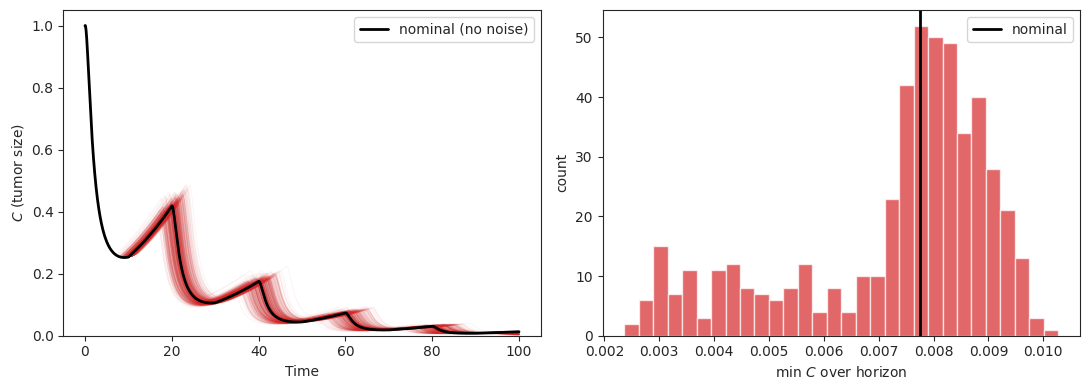

In [24]:
# Extra: robustness ensemble — 500 noisy runs vs. nominal schedule
import numpy as np
from scipy.integrate import odeint

def simulate_cycle(Ton, Toff, noise_level, T_horizon=100.0, rng=None, n_seg=200):
    rng = np.random.default_rng() if rng is None else rng
    y_cur = np.array([A_ss, B_ss, 1.0])
    t_cur = 0.0
    t_all, A_all, B_all, C_all = [], [], [], []
    while t_cur < T_horizon:
        for b1_phase, dur in ((b1_on, Ton), (b1, Toff)):   # ON then OFF
            seg = min(max(0.0, dur + rng.normal(0, noise_level)), T_horizon - t_cur)
            ts = np.linspace(0, seg, n_seg)
            s = odeint(lambda y, t: abc_rhs(t, y, b1_phase), y_cur, ts)
            t_all.append(t_cur + ts)
            A_all.append(s[:, 0]); B_all.append(s[:, 1]); C_all.append(s[:, 2])
            t_cur += seg; y_cur = s[-1]
            if t_cur >= T_horizon:
                break
    return (np.concatenate(t_all), np.concatenate(A_all),
            np.concatenate(B_all), np.concatenate(C_all))

rng = np.random.default_rng(0)
N = 500
runs = [simulate_cycle(10.0, 10.0, 1.0, rng=rng) for _ in range(N)]
t_nom, _, _, C_nom = simulate_cycle(10.0, 10.0, 0.0)   # noise-free reference

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

for t, A, B, C in runs:
    ax1.plot(t, C, color='C3', lw=0.6, alpha=0.06)
ax1.plot(t_nom, C_nom, color='k', lw=2, label='nominal (no noise)')
ax1.set(xlabel='Time', ylabel='$C$ (tumor size)', ylim=(0, None)); ax1.legend()

Cmin = np.array([C.min() for *_, C in runs])
ax2.hist(Cmin, bins=30, color='C3', alpha=0.7)
ax2.axvline(C_nom.min(), color='k', lw=2, label='nominal')
ax2.set(xlabel='min $C$ over horizon', ylabel='count'); ax2.legend()
plt.tight_layout(); plt.show()

## Supplementary: Full Analytical Derivation

*(Moved here from `abc_model.ipynb` — this is the SI material.)*

### SI: Tumor Growth vs. Decay Condition

We start with the tumor dynamics:
$$\frac{dC}{dt} = C\bigl(c_1 - c_2 (\mu - B)^+\bigr)$$

Dividing by $C > 0$ and integrating over one cycle $T = T_{on} + T_{off}$:
$$\ln\frac{C(T)}{C(0)} = c_1 T - c_2 \int_0^{T} (\mu - B(t))^+\,dt$$

Net tumor **decay** requires $C(T) < C(0)$, i.e.
$$c_1(T_{on}+T_{off}) < c_2 \int_0^{T_{on}+T_{off}} (\mu - B(t))^+\,dt$$

Because $B(t) > \mu$ after treatment is withdrawn, the integral is dominated by the on-phase:
$$S(T_{on}) \approx c_2 \int_0^{T_{on}} (\mu - B(t))\,dt$$

### SI: Explicit Solution for $B(t)$ During Treatment

Initial conditions at $t=0$ (off-treatment steady state):
$$A(0) = \frac{b_2\mu}{b_{1,\text{off}}}, \qquad B(0) = \mu$$

The $A$–$B$ subsystem reduces to a second-order ODE for $B$:
$$\ddot{B} + b_2 \dot{B} + a_1 b_{1,\text{on}} B = a_1 b_{1,\text{on}} \mu$$

General solution:
$$B(t) = \mu + K_1\bigl(e^{\lambda_1 t} - e^{\lambda_2 t}\bigr)$$

where $\lambda_{1,2} = \dfrac{-b_2 \pm \sqrt{b_2^2 - 4a_1 b_{1,\text{on}}}}{2}$ and

$$K_1 = \frac{b_2\mu\!\left(\dfrac{b_{1,\text{on}}}{b_{1,\text{off}}} - 1\right)}{\lambda_1 - \lambda_2}$$

### SI: Closed-Form Decay Integral

Substituting $B(t)$ into the decay integral:
$$S(T_{on}) = -c_2 K_1 \left[\frac{e^{\lambda_1 T_{on}}}{\lambda_1} - \frac{e^{\lambda_2 T_{on}}}{\lambda_2} - \frac{1}{\lambda_1} + \frac{1}{\lambda_2}\right]$$

As $T_{on} \to \infty$ (both eigenvalues have negative real parts, so exponentials vanish):
$$S_\infty = c_2 \frac{b_2\mu\!\left(1 - \dfrac{b_{1,\text{on}}}{b_{1,\text{off}}}\right)}{\lambda_1 \lambda_2}$$

This maximum possible decay per pulse is set by:
- $c_2$: tumor sensitivity to $B$ suppression
- $b_2\mu$: speed of initial $B$ drop
- $1 - b_{1,\text{on}}/b_{1,\text{off}}$: treatment depth (0 = no effect, 1 = full blockade)
- $1/(\lambda_1\lambda_2) = 1/(a_1 b_{1,\text{on}})$: inverse adaptation speed (slow adaptation → more accumulated decay)